# Time Series Practice 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf, pacf 
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

## 1. Load dataset

In [2]:
df = pd.read_csv(r'../datasets/raw/air_passengers.csv') 
df.head() 

,rownames,time,value
0,1,1949.000000,112
1,2,1949.083333,118
2,3,1949.166667,132
3,4,1949.250000,129
4,5,1949.333333,121


## 2. Feature engineering

In [3]:
df = df.drop(columns=['rownames'])  
df.head()  

,time,value
0,1949.000000,112
1,1949.083333,118
2,1949.166667,132
3,1949.250000,129
4,1949.333333,121


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   time    144 non-null    float64
 1   value   144 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 2.4 KB


In [5]:
df.describe()

,time,value
count,144.000000,144.000000
mean,1954.958333,280.298611
std,3.476109,119.966317
min,1949.000000,104.000000
25%,1951.979167,180.000000
50%,1954.958333,265.500000
75%,1957.937500,360.500000
max,1960.916667,622.000000


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
# xu li cot time
year = np.floor(df["time"]).astype(int)

month = (
    np.round((df["time"] - year) * 12).astype(int) + 1
)

# Chuyển thành datetime
df["date"] = pd.to_datetime({
    "year": year,
    "month": month,
    "day": 1
})

# Kiểm tra kết quả
print(df[["time", "date", "value"]].head(12))
print(df.dtypes)

           time       date  value
0   1949.000000 1949-01-01    112
1   1949.083333 1949-02-01    118
2   1949.166667 1949-03-01    132
3   1949.250000 1949-04-01    129
4   1949.333333 1949-05-01    121
5   1949.416667 1949-06-01    135
6   1949.500000 1949-07-01    148
7   1949.583333 1949-08-01    148
8   1949.666667 1949-09-01    136
9   1949.750000 1949-10-01    119
10  1949.833333 1949-11-01    104
11  1949.916667 1949-12-01    118
time            float64
value             int64
date     datetime64[us]
dtype: object


In [8]:
df = df.drop("time", axis=1)

In [9]:
df.head()

,value,date
0,112,1949-01-01
1,118,1949-02-01
2,132,1949-03-01
3,129,1949-04-01
4,121,1949-05-01


In [10]:
# Lấy cột date ra khỏi DataFrame
date = df.pop("date")

# Chèn date vào vị trí ngay trước value
df.insert(df.columns.get_loc("value"), "date", date)

In [11]:
df.head()

,date,value
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


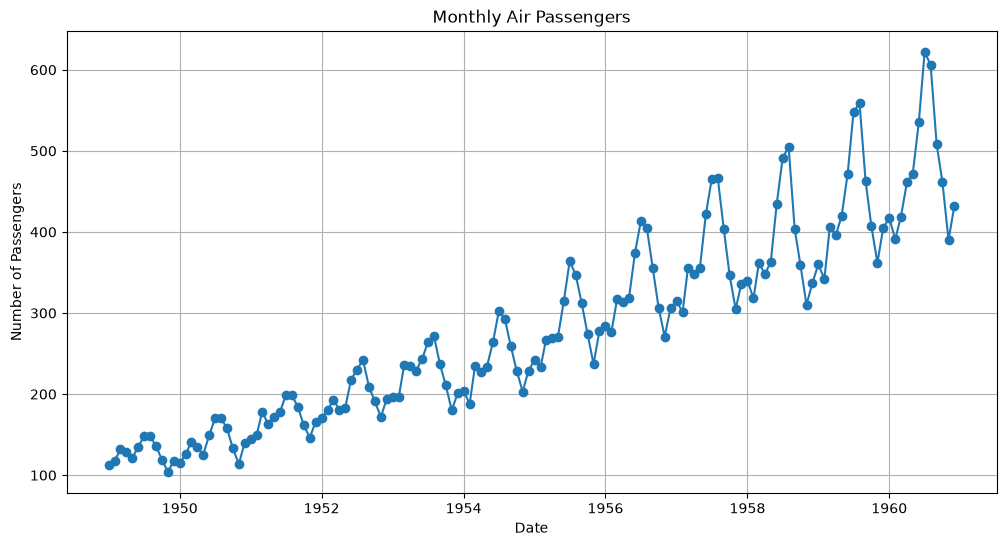

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(df["date"], df["value"], marker="o", linestyle="-")
plt.title("Monthly Air Passengers")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.grid()
plt.show()

##### Biểu đồ đường (line chart) này thể hiện chuỗi thời gian về số lượng hành khách đi máy bay hàng tháng ("Monthly Air Passengers") từ khoảng năm 1949 đến năm 1961.
Trục hoành (X-axis): Biểu diễn dòng thời gian (Date), được đánh dấu mốc chẵn mỗi 2 năm (1950, 1952, 1954, 1956, 1958, 1960). Mỗi điểm chấm trên đường biểu diễn dữ liệu của một tháng.
Trục tung (Y-axis): Biểu diễn số lượng hành khách (Number of Passengers), với thang đo chia khoảng 100 đơn vị, kéo dài từ 100 đến hơn 600.
Các đặc tính quan trọng được thể hiện qua biểu đồ:Xu hướng tăng trưởng rõ rệt (Upward Trend): Dữ liệu cho thấy sự gia tăng liên tục và mạnh mẽ về tổng số lượng hành khách qua các năm. Khởi đầu ở mức dao động xung quanh 100 - 150 hành khách, con số này đã tăng lên mức trên 400 - 600 hành khách vào những năm đầu thập niên 1960.
Tính mùa vụ cố định (Seasonality): Biểu đồ xuất hiện các chu kỳ lặp đi lặp lại rất đều đặn theo từng năm. Trong mỗi khoảng thời gian một năm, luôn xuất hiện một đỉnh nhọn (số lượng hành khách tăng vọt, thường rơi vào mùa du lịch) và một đáy (số lượng hành khách sụt giảm).
Biên độ dao động tăng dần (Multiplicative Effect): Khi xu hướng chung đi lên, khoảng cách giữa đỉnh và đáy của từng chu kỳ mùa vụ cũng mở rộng theo. Ở những năm 1950, mức chênh lệch giữa tháng cao điểm và thấp điểm khá nhỏ (chỉ vài chục hành khách). Tuy nhiên, đến năm 1960, sự chênh lệch này trở nên rất lớn (hơn 200 hành khách giữa đỉnh và đáy). 

# 3. ACF , PACF 40 flags

## Công thức tính ACF và PACF

### 1. ACF (Autocorrelation Function)

ACF đo lường mức độ tương quan tuyến tính giữa chuỗi thời gian tại thời điểm hiện tại và chính chuỗi đó tại một độ trễ \(k\).

**Công thức:**

$$
r_k = \frac{\displaystyle\sum_{t=k+1}^{n}(X_t-\bar{X})(X_{t-k}-\bar{X})}{\displaystyle\sum_{t=1}^{n}(X_t-\bar{X})^2}
$$

Trong đó:

- \(r_k\): hệ số tự tương quan tại độ trễ \(k\).
- \(X_t\): giá trị quan sát tại thời điểm \(t\).
- \(X_{t-k}\): giá trị quan sát tại thời điểm trễ \(k\).
- \(\bar{X}\): giá trị trung bình của chuỗi thời gian.
- \(n\): tổng số quan sát.
- \(k\): độ trễ (*lag*).

**Ý nghĩa:**

- \(r_k \approx 1\): tương quan dương mạnh.
- \(r_k \approx -1\): tương quan âm mạnh.
- \(r_k \approx 0\): tương quan tuyến tính yếu hoặc không đáng kể.

ACF được sử dụng để phân tích sự phụ thuộc theo thời gian và hỗ trợ lựa chọn bậc MA (\(q\)) trong mô hình ARIMA.

### 2. PACF (Partial Autocorrelation Function)

PACF đo lường mối tương quan tuyến tính trực tiếp giữa \(X_t\) và \(X_{t-k}\), sau khi loại bỏ ảnh hưởng tuyến tính của các độ trễ trung gian \(1,2,\ldots,k-1\).

**Công thức tổng quát:**

$$
\phi_{kk} = \operatorname{Corr}
\left(
X_t, X_{t-k}
\mid X_{t-1},\ldots,X_{t-k+1}
\right)
$$

Trong thực tế, PACF có thể được tính thông qua mô hình hồi quy tự hồi quy AR(\(k\)):

$$
X_t = c + \phi_{k1}X_{t-1}
+\phi_{k2}X_{t-2}
+\cdots+\phi_{kk}X_{t-k}+\varepsilon_t
$$

Trong đó:

- \(X_t\): giá trị hiện tại của chuỗi thời gian.
- \(X_{t-i}\): giá trị tại độ trễ \(i\).
- \(\phi_{ki}\): hệ số hồi quy tương ứng với độ trễ \(i\) trong mô hình AR(\(k\)).
- \(\phi_{kk}\): hệ số PACF tại lag \(k\).
- \(c\): hằng số.
- \(\varepsilon_t\): sai số ngẫu nhiên.

**Ý nghĩa:**

PACF cho biết mức độ liên hệ trực tiếp giữa hai thời điểm sau khi kiểm soát ảnh hưởng của các lag trung gian. Nó thường được sử dụng để hỗ trợ lựa chọn bậc AR (\(p\)) trong mô hình ARIMA.

In [13]:
series = df["value"]

# Tính ACF
acf_values = acf(series, nlags=40)

# Tính PACF
pacf_values = pacf(series, nlags=40, method="ywm")

print("ACF:", acf_values)
print("PACF:", pacf_values)

ACF: [1.         0.94804734 0.87557484 0.80668116 0.75262542 0.71376997
 0.6817336  0.66290439 0.65561048 0.67094833 0.70271992 0.74324019
 0.76039504 0.71266087 0.64634228 0.58592342 0.53795519 0.49974753
 0.46873401 0.44987066 0.4416288  0.45722376 0.48248203 0.51712699
 0.53218983 0.49397569 0.43772134 0.3876029  0.34802503 0.31498388
 0.28849682 0.27080187 0.26429011 0.27679934 0.2985215  0.32558712
 0.3370236  0.30333486 0.25397708 0.21065534 0.17217092]
PACF: [ 1.          0.94804734 -0.22942187  0.03814778  0.09378544  0.0736067
  0.0077276   0.12559713  0.08995134  0.23248854  0.16605126  0.17127442
 -0.1354311  -0.53969124 -0.02661014  0.09076498  0.02495556  0.03251557
  0.07343264  0.04844211 -0.04554168  0.04575294 -0.10017888  0.05243494
  0.04801413 -0.16274616 -0.03613503  0.06642377  0.00617612  0.00753714
  0.01935049 -0.01025146 -0.01831018 -0.02900136 -0.01480497 -0.0477246
  0.04620366 -0.0666976  -0.00229644  0.0160981  -0.08833969]


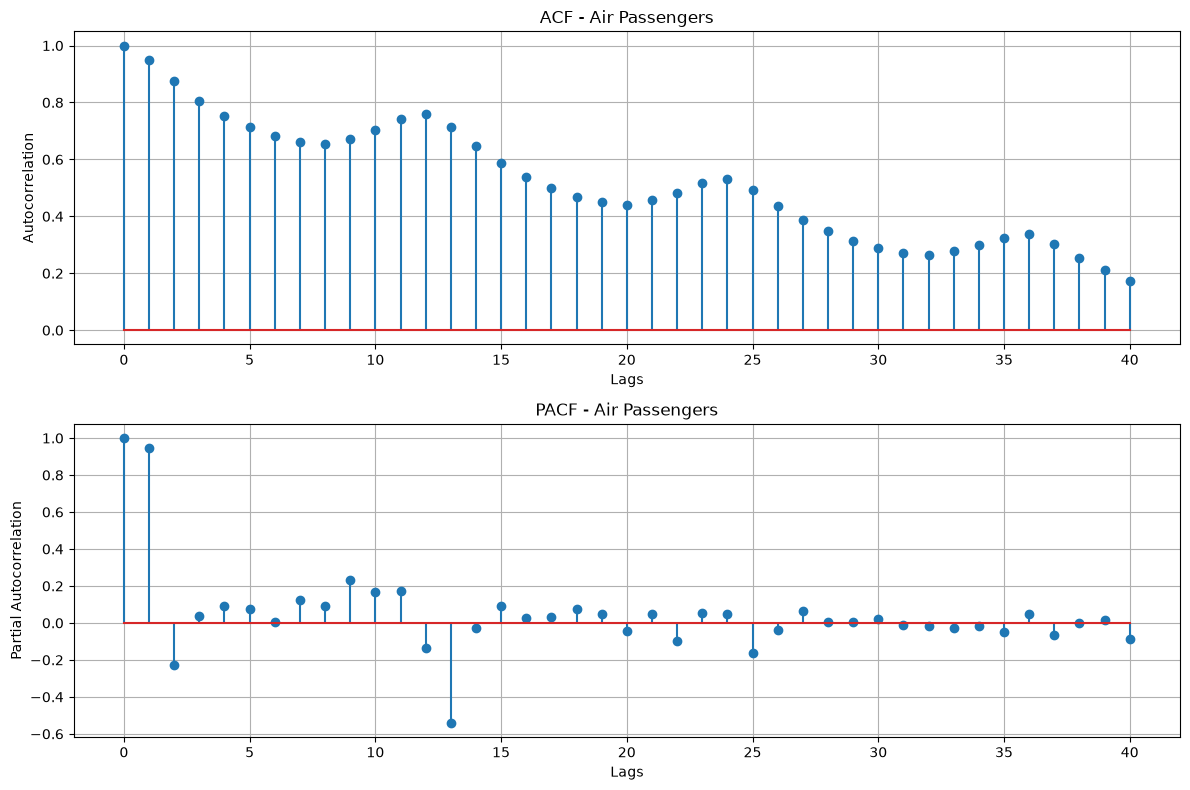

In [14]:
lags = np.arange(41)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Vẽ ACF
axes[0].stem(lags, acf_values) # biểu đồ vạch mẫu
axes[0].set_title("ACF - Air Passengers")
axes[0].set_xlabel("Lags")
axes[0].set_ylabel("Autocorrelation")
axes[0].grid(True)

# Vẽ PACF
axes[1].stem(lags, pacf_values) # biểu đồ vạch mẫu
axes[1].set_title("PACF - Air Passengers")
axes[1].set_xlabel("Lags")
axes[1].set_ylabel("Partial Autocorrelation")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Phân tích ACF và PACF của chuỗi thời gian Air Passengers

### 1. Mục đích

ACF (Autocorrelation Function) và PACF (Partial Autocorrelation Function) được sử dụng để phân tích mối quan hệ giữa giá trị hiện tại và các giá trị trong quá khứ của một chuỗi thời gian.

- **ACF:** Đo hệ số tương quan giữa chuỗi thời gian hiện tại và chuỗi bị dịch chuyển theo một độ trễ (*lag*) nhất định.
- **PACF:** Đo hệ số tương quan riêng phần giữa giá trị hiện tại và giá trị tại một lag, sau khi loại bỏ ảnh hưởng tuyến tính của các lag trung gian.

Trong dataset Air Passengers, mỗi quan sát tương ứng với số lượng hành khách hàng không trong một tháng. Phân tích ACF và PACF giúp nhận biết tính phụ thuộc theo thời gian, xu hướng và khả năng tồn tại của tính mùa vụ, đồng thời hỗ trợ lựa chọn tham số cho mô hình ARIMA hoặc SARIMA.

### 2. Phân tích biểu đồ ACF

**Đặc điểm quan sát được:**

- **Lag 0:** Hệ số tương quan bằng 1 vì chuỗi dữ liệu luôn tương quan hoàn hảo với chính nó.
- **Lag 1–8:** Hệ số tương quan giảm từ khoảng 0.95 xuống khoảng 0.65, nhưng vẫn duy trì ở mức cao. Điều này cho thấy số lượng hành khách trong một tháng có mối quan hệ mạnh với số lượng hành khách của các tháng trước đó.
- **Lag 9–14:** Hệ số tương quan tăng trở lại, đạt khoảng 0.75 tại lag 12, rồi giảm dần. Sự dao động này có thể phản ánh cấu trúc mùa vụ của dữ liệu.
- **Lag 15–24:** Hệ số tương quan tiếp tục giảm nhưng xuất hiện một vùng tăng nhẹ quanh lag 22–24. Đây có thể là dấu hiệu của sự lặp lại theo chu kỳ.
- **Lag 25–40:** Hệ số tương quan nhìn chung tiếp tục giảm và vẫn dương, từ khoảng 0.49 tại lag 25 xuống khoảng 0.17 tại lag 40.

**Nhận xét:**

ACF giảm tương đối chậm và duy trì giá trị dương trong nhiều độ trễ. Đây là đặc điểm thường gặp ở chuỗi thời gian có xu hướng hoặc chưa dừng (*non-stationary*).

Ngoài ra, các vùng tăng tương quan quanh lag 12 và những độ trễ gần bội số của 12 gợi ý khả năng tồn tại tính mùa vụ theo năm, phù hợp với dữ liệu hành khách được ghi nhận theo tháng.

Tuy nhiên, chỉ dựa vào ACF chưa thể kết luận chắc chắn rằng chuỗi có tính mùa vụ hoặc chưa dừng. Cần kết hợp với biểu đồ chuỗi thời gian và các kiểm định tính dừng.

### 3. Phân tích biểu đồ PACF

**Đặc điểm quan sát được:**

- **Lag 0:** PACF bằng 1, tương tự ACF.
- **Lag 1:** PACF khoảng 0.94, cho thấy mối quan hệ tuyến tính riêng phần rất mạnh giữa giá trị hiện tại và giá trị ở tháng trước.
- **Lag 2:** PACF âm, khoảng -0.23, thể hiện mối quan hệ riêng phần ngược chiều tại độ trễ này sau khi kiểm soát các lag trung gian.
- **Lag 3–12:** Các hệ số dao động quanh 0, phần lớn có độ lớn tương đối nhỏ, nhưng vẫn xuất hiện một số giá trị đáng chú ý, chẳng hạn lag 9 khoảng 0.23.
- **Lag 13:** PACF giảm mạnh xuống khoảng -0.54. Đây là một điểm nổi bật trên biểu đồ và cần được kiểm tra bằng khoảng tin cậy thống kê.
- **Lag 14–40:** Các hệ số phần lớn dao động quanh 0, mặc dù vẫn có một số giá trị âm hoặc dương đáng chú ý, chẳng hạn lag 25 khoảng -0.16.

**Nhận xét:**

PACF cho thấy mối liên hệ riêng phần rất mạnh ở lag 1. Tuy nhiên, các hệ số ở những lag tiếp theo không tạo thành một điểm cắt rõ ràng, đơn giản như thường thấy trong ví dụ AR thuần túy trên chuỗi dừng.

Giá trị âm lớn tại lag 13 có thể liên quan đến cấu trúc tương quan phức tạp hoặc đặc điểm của chuỗi chưa dừng. Không nên kết luận lag 13 là tham số AR phù hợp chỉ dựa vào độ lớn của cột này.

### 4. So sánh ACF và PACF

| Tiêu chí | ACF | PACF |
|---|---|---|
| Mục đích | Đo tương quan giữa chuỗi và phiên bản trễ của nó | Đo tương quan riêng phần tại từng lag |
| Đặc điểm nổi bật | Giảm chậm và duy trì giá trị dương qua nhiều lag | Lag 1 rất cao; các lag sau dao động quanh 0 với một số ngoại lệ |
| Hàm ý | Có thể tồn tại xu hướng và cấu trúc mùa vụ | Chưa có điểm cắt rõ ràng để xác định bậc AR |
| Ứng dụng | Hỗ trợ lựa chọn bậc MA và thành phần mùa vụ | Hỗ trợ lựa chọn bậc AR và thành phần mùa vụ |

### 5. Kết luận

Từ hai biểu đồ có thể rút ra các nhận xét chính:

1. Chuỗi Air Passengers có sự phụ thuộc đáng kể giữa các thời điểm liên tiếp, thể hiện qua ACF dương và giảm chậm.
2. Các dao động gần lag 12 và các bội số của 12 gợi ý khả năng tồn tại mùa vụ với chu kỳ 12 tháng.
3. PACF có hệ số rất cao tại lag 1, nhưng hình dạng tổng thể chưa đủ rõ để xác định trực tiếp bậc AR.
4. Chuỗi gốc có dấu hiệu chưa dừng, có thể do xu hướng tăng và cấu trúc mùa vụ.



## 3. Kết luận

### 3.1. Chuỗi có tự tương quan mạnh không?

Có. Biểu đồ ACF cho thấy hệ số tự tương quan tại lag 1 khoảng 0.95 và giảm tương đối chậm khi độ trễ tăng. Ngay cả tại lag 12, hệ số tương quan vẫn khoảng 0.74.

Điều này cho thấy số lượng hành khách tại một tháng có mối quan hệ mạnh với các tháng trước đó. Chuỗi có cấu trúc phụ thuộc theo thời gian rõ rệt, thay vì các quan sát độc lập với nhau.

### 3.2. Có xu hướng và mùa vụ thể hiện qua ACF/PACF không?

- **Xu hướng:** ACF giảm chậm và duy trì giá trị dương trong nhiều lag, gợi ý chuỗi có thể chưa dừng do xu hướng tăng theo thời gian.
- **Mùa vụ:** ACF có sự tăng trở lại quanh lag 12 và các vùng dao động đáng chú ý gần những bội số của 12. Đây là dấu hiệu gợi ý chu kỳ mùa vụ hằng năm của dữ liệu hành khách theo tháng.
- **PACF:** Hệ số tại lag 1 rất cao, trong khi các lag tiếp theo dao động quanh 0 với một số ngoại lệ, đáng chú ý là lag 13 có giá trị âm lớn. PACF chưa thể hiện một điểm cắt rõ ràng để xác định trực tiếp bậc AR.

Các nhận xét trên là dấu hiệu ban đầu. Cần kết hợp biểu đồ chuỗi thời gian và kiểm định ADF để đánh giá tính dừng; đồng thời, nên phân tích ACF/PACF sau sai phân để xác định cấu trúc mùa vụ rõ hơn.

### 3.3. Lag nào quan trọng nhất?

- **Lag 1:** Quan trọng nhất trên cả ACF và PACF. ACF khoảng 0.95 và PACF khoảng 0.94, cho thấy mối liên hệ mạnh giữa tháng hiện tại và tháng liền trước.
- **Lag 12:** Đáng chú ý trên ACF, với hệ số khoảng 0.74. Điều này gợi ý mối liên hệ giữa các tháng cách nhau một năm.
- **Lag 13:** PACF khoảng -0.54, là một giá trị nổi bật cần kiểm tra thêm. Tuy nhiên, không thể khẳng định lag này có ý nghĩa thống kê nếu chưa có khoảng tin cậy.

**Tóm lại:** Lag 1 thể hiện sự phụ thuộc ngắn hạn mạnh nhất, còn lag 12 là dấu hiệu đáng chú ý về mùa vụ. Với dữ liệu Air Passengers, nên kiểm tra sai phân bậc 1 và sai phân mùa vụ bậc 12 trước khi lựa chọn tham số cho mô hình SARIMA.

In [15]:
# Sinh 1000 điểm white noise
np.random.seed(42)
white_noise = np.random.normal(loc=0, scale=1, size=1000)

# Chuyển thành Series
white_noise = pd.Series(white_noise, name="white_noise")

# Kiểm tra dữ liệu
print(white_noise.head())

0    0.496714
1   -0.138264
2    0.647689
3    1.523030
4   -0.234153
Name: white_noise, dtype: float64


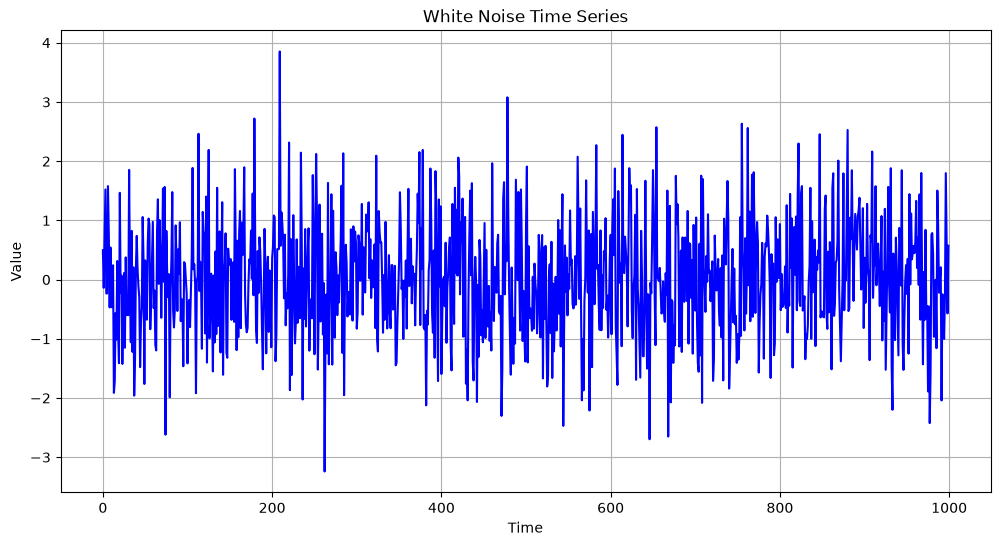

In [16]:
white_noise.plot(figsize=(12, 6), title="White Noise Time Series", color='blue')
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid()
plt.show()

### Công thức tính ngưỡng tin cậy 95% của ACF

Đối với chuỗi White Noise có \(n\) quan sát, ngưỡng tin cậy 95% xấp xỉ được tính bằng:

$$
CI_{95\%} = \pm \frac{1.96}{\sqrt{n}}
$$

Trong đó:

- \(CI_{95\%}\): ngưỡng tin cậy 95%.
- \(1.96\): giá trị tới hạn của phân phối chuẩn ở mức tin cậy 95% hai phía.
- \(n\): số lượng quan sát trong chuỗi thời gian.

**Ví dụ:** Với \(n = 1000\) quan sát:

$$
CI_{95\%} = \pm \frac{1.96}{\sqrt{1000}}
\approx \pm 0.062
$$

**Cách diễn giải:**

- Nếu hệ số ACF nằm trong khoảng \([-0.062, 0.062]\), chưa có đủ bằng chứng để kết luận hệ số tự tương quan tại lag đó khác 0 ở mức ý nghĩa 5%.
- Nếu hệ số ACF nằm ngoài khoảng này, hệ số tự tương quan tại lag đó có thể có ý nghĩa thống kê ở mức 5%.

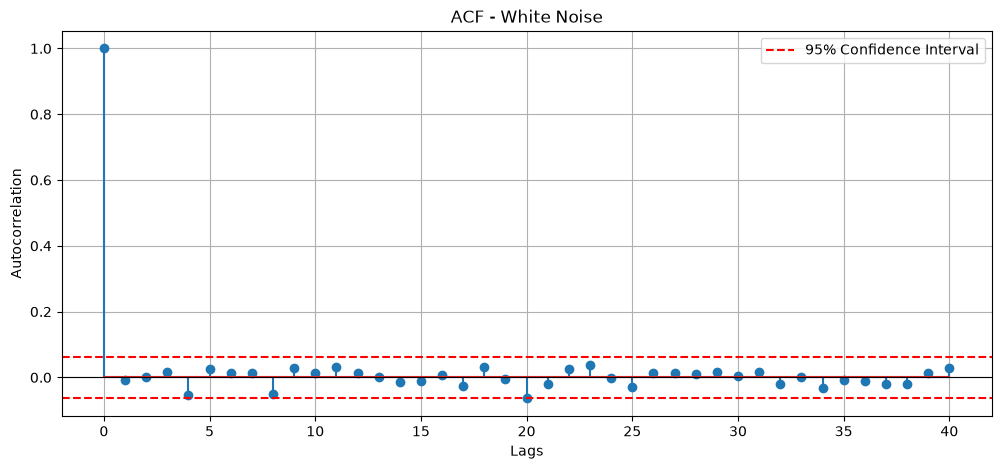

Ngưỡng tin cậy 95%: ±0.0620


In [17]:
# Tính ACF đến 40 lags
n = len(white_noise)
acf_values = acf(white_noise, nlags=40, fft=True)

# Ngưỡng tin cậy 95%
confidence = 1.96 / np.sqrt(n)

# Vẽ ACF
lags = np.arange(len(acf_values))

plt.figure(figsize=(12, 5))
plt.stem(lags, acf_values)
plt.axhline(y=confidence, color="red", linestyle="--",
            label="95% Confidence Interval")
plt.axhline(y=-confidence, color="red", linestyle="--")
plt.axhline(y=0, color="black", linewidth=0.8)

plt.title("ACF - White Noise")
plt.xlabel("Lags")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid(True)
plt.show()

print(f"Ngưỡng tin cậy 95%: ±{confidence:.4f}")

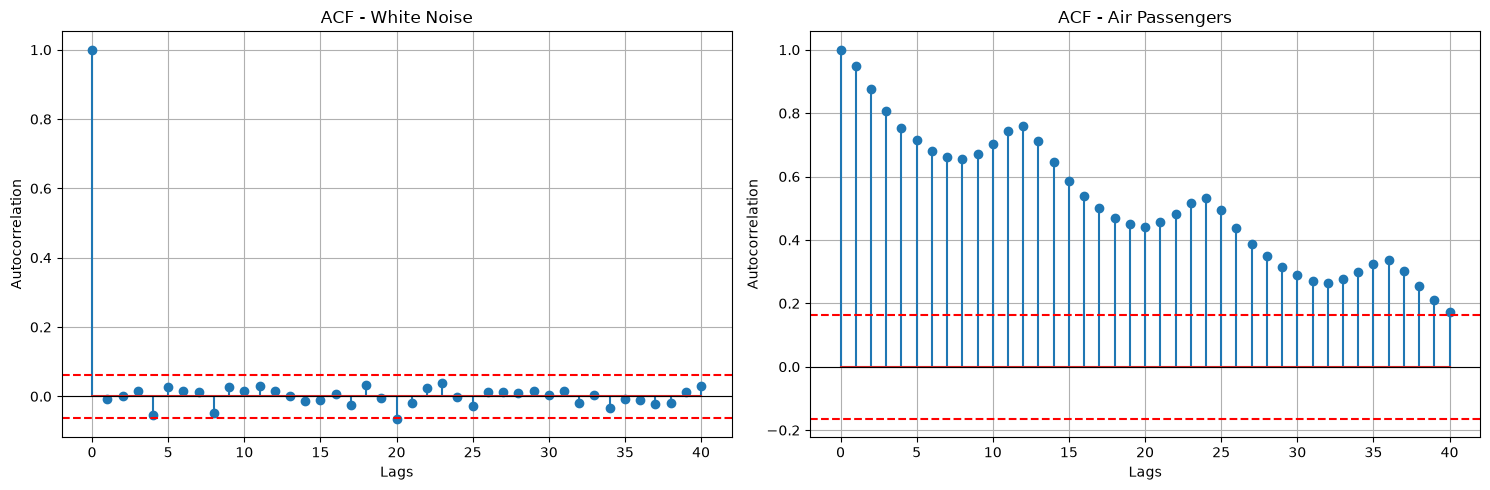

In [18]:
# Tính ACF của Air Passengers
air_passengers = df["value"]
air_acf = acf(air_passengers, nlags=40, fft=True)

# Vẽ hai biểu đồ cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ACF White Noise
axes[0].stem(np.arange(len(acf_values)), acf_values)
axes[0].axhline(confidence, color="red", linestyle="--")
axes[0].axhline(-confidence, color="red", linestyle="--")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("ACF - White Noise")
axes[0].set_xlabel("Lags")
axes[0].set_ylabel("Autocorrelation")
axes[0].grid(True)

# ACF Air Passengers
air_confidence = 1.96 / np.sqrt(len(air_passengers))

axes[1].stem(np.arange(len(air_acf)), air_acf)
axes[1].axhline(air_confidence, color="red", linestyle="--")
axes[1].axhline(-air_confidence, color="red", linestyle="--")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("ACF - Air Passengers")
axes[1].set_xlabel("Lags")
axes[1].set_ylabel("Autocorrelation")
axes[1].grid(True)

plt.tight_layout()
plt.show()

1. White Noise có các hệ số ACF tại hầu hết các lag dao động quanh 0, trong khi ACF của Air Passengers duy trì giá trị dương cao qua nhiều lag.
2. Phần lớn các lag của White Noise nằm trong ngưỡng tin cậy 95%, mặc dù một vài lag có thể vượt ngưỡng do ngẫu nhiên.
3. ACF của Air Passengers giảm chậm, cho thấy chuỗi có sự phụ thuộc theo thời gian và có thể chưa dừng.
4. Air Passengers có dấu hiệu mùa vụ với chu kỳ 12 tháng, thể hiện qua sự tăng trở lại của ACF quanh lag 12 và các bội số của 12.
5. White Noise thường không chứa cấu trúc tự tương quan tuyến tính, trong khi Air Passengers có xu hướng và mùa vụ nên cần xử lý trước khi xây dựng mô hình dự báo.

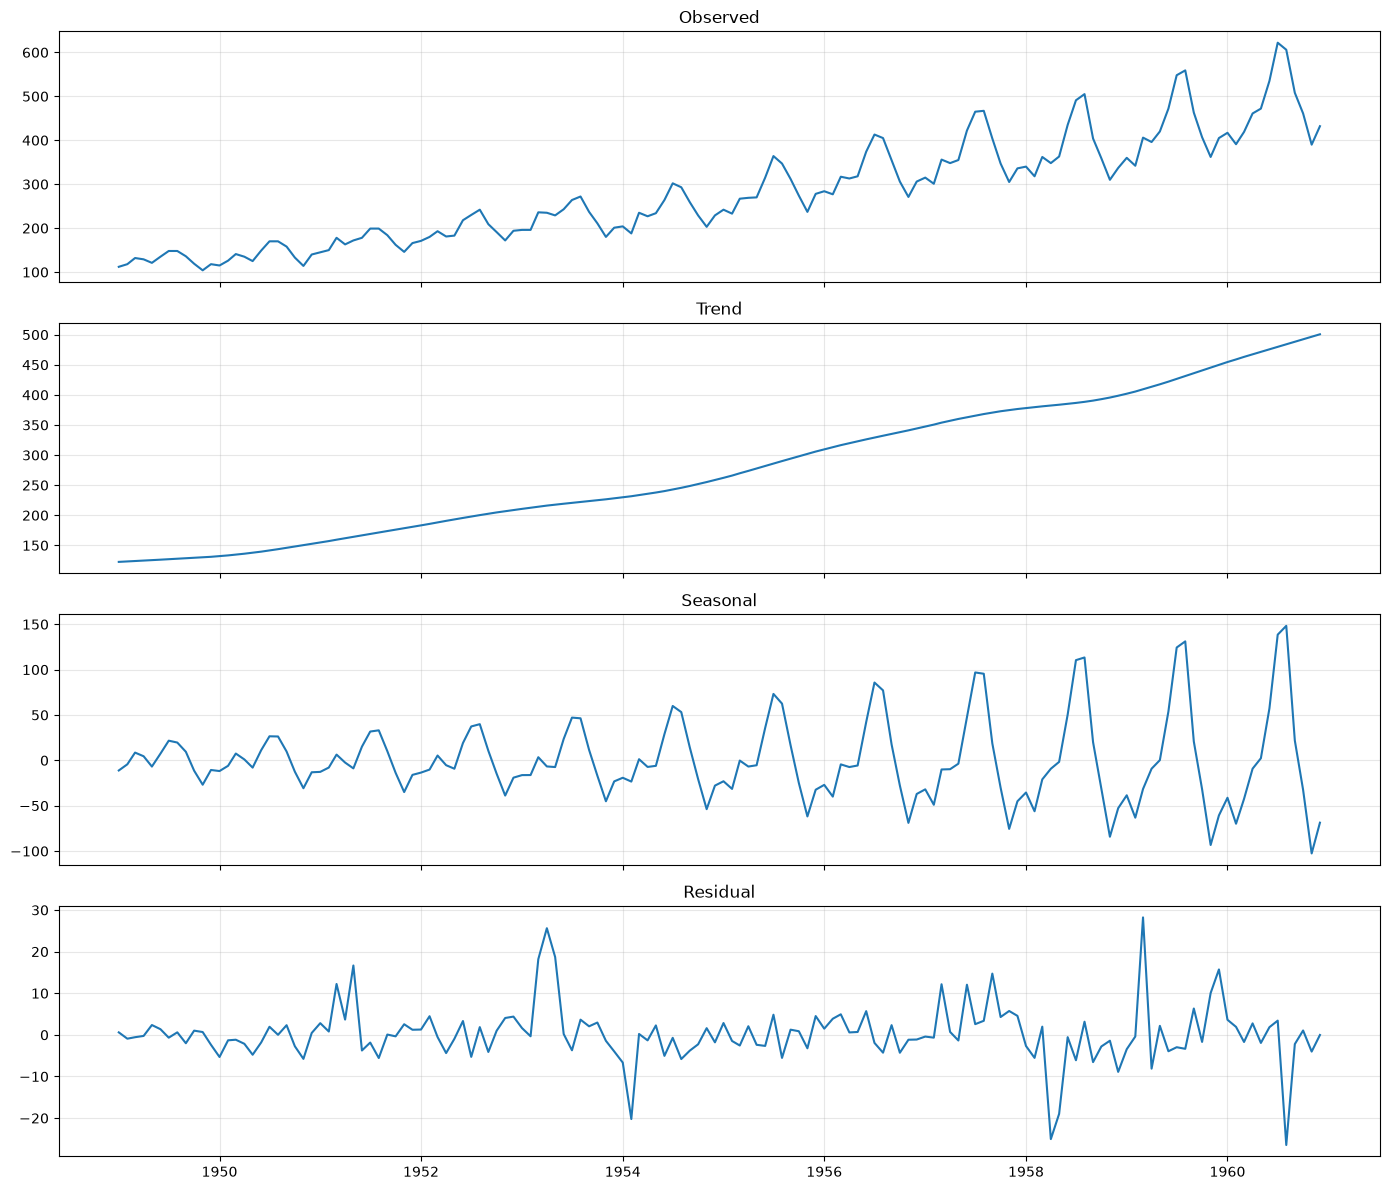

In [19]:
# Đưa date thành index
series = df.set_index("date")["value"].asfreq("MS")

# STL decomposition: chu kỳ mùa vụ 12 tháng
stl = STL(series, period=12, robust=True)
result = stl.fit()

# Vẽ 4 thành phần
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

axes[0].plot(result.observed)
axes[0].set_title("Observed")

axes[1].plot(result.trend)
axes[1].set_title("Trend")

axes[2].plot(result.seasonal)
axes[2].set_title("Seasonal")

axes[3].plot(result.resid)
axes[3].set_title("Residual")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Phân tích kết quả Time Series Decomposition

### 1. Xu hướng tăng/giảm (Trend)

Thành phần Trend cho thấy xu hướng tăng rõ rệt trong giai đoạn 1949–1960. Điều này phản ánh số lượng hành khách hàng không tăng dần theo thời gian, cho thấy nhu cầu đi lại bằng đường hàng không ngày càng lớn.

### 2. Mức độ mùa vụ (Seasonal)

Thành phần Seasonal thể hiện mô hình biến động lặp lại theo chu kỳ 12 tháng. Số lượng hành khách thường tăng vào một số tháng nhất định và giảm vào các tháng khác. Biên độ dao động mùa vụ đáng chú ý, cho thấy dữ liệu có tính mùa vụ rõ rệt.

### 3. Phần dư có giống White Noise không?

Thành phần Residual được kỳ vọng dao động quanh giá trị 0. Tuy nhiên, chỉ quan sát biểu đồ chưa đủ để kết luận phần dư là White Noise. Cần kiểm tra xem phần dư có còn tự tương quan hoặc cấu trúc theo thời gian hay không, chẳng hạn bằng biểu đồ ACF và kiểm định Ljung–Box.

### 4. Kết luận

Chuỗi Air Passengers có xu hướng tăng và tính mùa vụ theo chu kỳ 12 tháng. Phương pháp STL giúp tách riêng các thành phần này để hiểu rõ hơn cấu trúc dữ liệu. Phần dư cần được kiểm tra thêm để đánh giá liệu xu hướng và mùa vụ đã được mô hình hóa đầy đủ hay chưa.

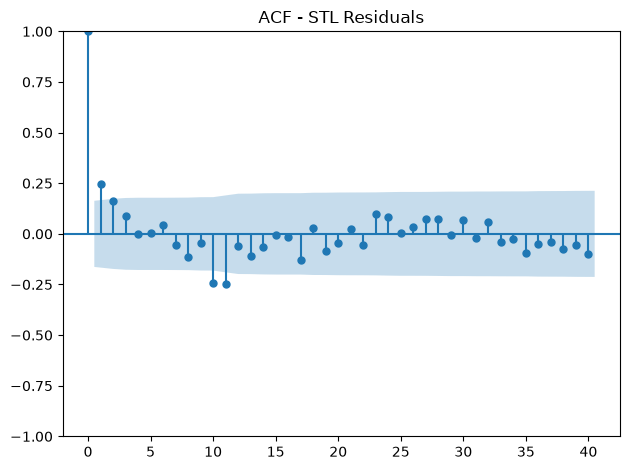

      lb_stat  lb_pvalue
12  36.817920   0.000239
24  47.347441   0.003038


In [20]:
residual = result.resid.dropna()

# Vẽ ACF của phần dư
plot_acf(residual, lags=40)
plt.title("ACF - STL Residuals")
plt.tight_layout()
plt.show()

# Kiểm định Ljung-Box
lb_result = acorr_ljungbox(
    residual,
    lags=[12, 24],
    return_df=True
)

print(lb_result)

#### p-value ≤ 0.05: có bằng chứng cho thấy phần dư vẫn còn tự tương quan.

In [21]:
# Sắp xếp dữ liệu theo thời gian
data = df[["date", "value"]].copy()
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").set_index("date")

# Lưu dữ liệu gốc để so sánh
original = data["value"].copy()

# Tạo missing giả lập tại một số vị trí
data_missing = data.copy()
missing_idx = data_missing.index[[10, 25, 50, 80]]

data_missing.loc[missing_idx, "value"] = np.nan

In [22]:
print("Số lượng missing trước xử lý:")
print(data_missing.isna().sum())

print("Tỷ lệ missing (%):")
print(data_missing.isna().mean() * 100)

Số lượng missing trước xử lý:
value    4
dtype: int64
Tỷ lệ missing (%):
value    2.777778
dtype: float64


In [23]:
data_ffill = data_missing.copy()
data_ffill["value"] = data_ffill["value"].ffill()

print("Missing sau Forward-fill:")
print(data_ffill.isna().sum())

Missing sau Forward-fill:
value    0
dtype: int64


In [24]:
data_interp = data_missing.copy()
data_interp["value"] = data_interp["value"].interpolate(
    method="linear"
)

print("Missing sau Interpolation:")
print(data_interp.isna().sum())

Missing sau Interpolation:
value    0
dtype: int64


Định nghĩa
- Phương thức df.ffill() (Forward Fill) trong Pandas được dùng để điền các giá trị thiếu (NaN) bằng cách lan truyền giá trị hợp lệ gần nhất đứng trước nó.
- Interpolation (phép nội suy) là phương pháp ước tính một giá trị chưa biết nằm trong khoảng giữa các giá trị đã biết trong một tập dữ liệu hoặc chuỗi số


So sánh:
- ffill(): đơn giản, giữ giá trị trước đó nhưng có thể tạo đoạn nằm ngang.
- interpolate(): ước lượng giá trị giữa các điểm đã biết, thường tạo đường biến động mượt hơn.
- Nếu missing nằm ở đầu chuỗi, ffill() không xử lý được các giá trị đó. Nội suy tuyến tính mặc định cũng không điền các giá trị thiếu ở đầu chuỗi.

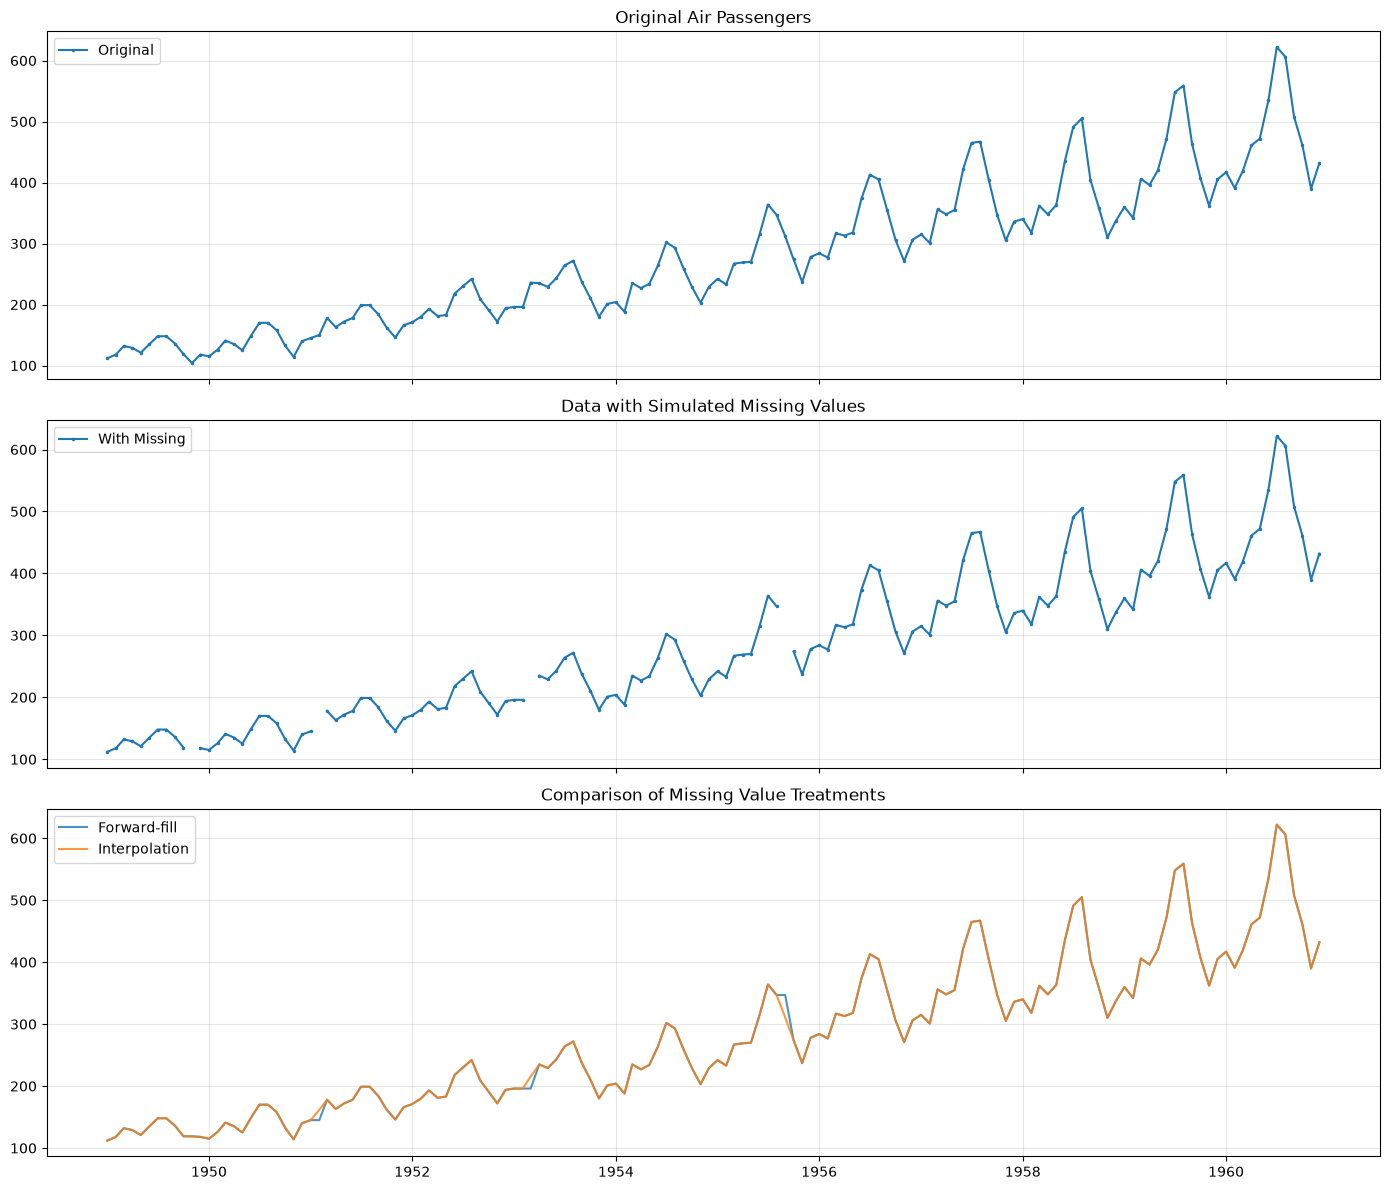

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

axes[0].plot(original, label="Original", marker=".", markersize=3)
axes[0].set_title("Original Air Passengers")
axes[0].legend()

axes[1].plot(data_missing["value"], label="With Missing",
             marker=".", markersize=3)
axes[1].set_title("Data with Simulated Missing Values")
axes[1].legend()

axes[2].plot(data_ffill["value"], label="Forward-fill", alpha=0.8)
axes[2].plot(data_interp["value"], label="Interpolation", alpha=0.8)
axes[2].set_title("Comparison of Missing Value Treatments")
axes[2].legend()

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# Sử dụng chuỗi đã nội suy
series = data_interp["value"]

window = 12

rolling_mean = series.rolling(
    window=window,
    center=True,
    min_periods=6
).mean()

rolling_var = series.rolling(
    window=window,
    center=True,
    min_periods=6
).var()

rolling_std = np.sqrt(rolling_var)

# Đánh dấu điểm lệch khỏi rolling mean quá 3 độ lệch chuẩn
outlier_rolling = (
    (series - rolling_mean).abs() > 3 * rolling_std
)

print("Số outliers theo Rolling Mean/Std:",
      outlier_rolling.sum())

Số outliers theo Rolling Mean/Std: 0


## 1. Rolling Mean (Trung bình trượt)

### Ý nghĩa

- **Làm mịn dữ liệu:** Giảm ảnh hưởng của các biến động ngắn hạn hoặc nhiễu để quan sát xu hướng (*trend*) dài hạn của chuỗi thời gian rõ hơn.
- **Ứng dụng:** Phân tích kỹ thuật chứng khoán (đường trung bình động - MA), dự báo thời tiết và theo dõi chỉ số hiệu suất hệ thống.

### Công thức tính

Cho chuỗi thời gian:

$$
X = \{x_1, x_2, \ldots, x_t, \ldots\}
$$

Với cửa sổ trượt (*window size*) có độ dài \(k\), Rolling Mean tại thời điểm \(t\) là trung bình cộng của \(k\) giá trị gần nhất:

$$
M_t = \frac{1}{k}\sum_{i=0}^{k-1}x_{t-i}
$$

Trong đó:

- \(M_t\): giá trị trung bình trượt tại thời điểm \(t\).
- \(x_{t-i}\): giá trị quan sát tại thời điểm \(t-i\).
- \(k\): số lượng quan sát trong cửa sổ trượt.

**Ví dụ:** Nếu \(k=3\), tại thời điểm \(t=5\):

$$
M_5 = \frac{x_5+x_4+x_3}{3}
$$

Khi chuyển sang thời điểm tiếp theo, cửa sổ trượt dịch chuyển một bước và tính lại trung bình từ ba quan sát gần nhất.

## 2. Rolling Variance (Phương sai trượt)

### Ý nghĩa

- **Đo lường độ biến động (*volatility*):** Cho biết mức độ phân tán của dữ liệu trong cửa sổ trượt quanh giá trị trung bình của cửa sổ đó.
- **Phát hiện bất thường:** Nếu phương sai trượt tăng đột ngột, dữ liệu có thể đang trải qua giai đoạn biến động mạnh, chẳng hạn biến động giá trên thị trường tài chính.

### Công thức tính

Tương tự phương sai mẫu thông thường, Rolling Variance chỉ tính toán trên \(k\) quan sát gần nhất tại mỗi thời điểm.

Công thức phương sai trượt mẫu hiệu chỉnh:

$$
V_t = \frac{1}{k-1}
\sum_{i=0}^{k-1}(x_{t-i}-M_t)^2
$$

Trong đó:

- \(V_t\): phương sai trượt tại thời điểm \(t\).
- \(x_{t-i}\): giá trị quan sát tại thời điểm \(t-i\).
- \(M_t\): trung bình của \(k\) quan sát trong cửa sổ tại thời điểm \(t\).
- \(k\): số lượng quan sát trong cửa sổ trượt.
- \(k-1\): bậc tự do khi tính phương sai mẫu hiệu chỉnh.

**Lưu ý:** Cần có ít nhất \(k=2\) quan sát để tính phương sai mẫu hiệu chỉnh.

## 3. Kết luận

Rolling Mean giúp quan sát xu hướng của chuỗi thời gian bằng cách làm mịn các biến động ngắn hạn. Trong khi đó, Rolling Variance giúp theo dõi sự thay đổi về mức độ biến động trong từng khoảng thời gian.



IQR (Interquartile Range) xác định outliers dựa trên khoảng tứ phân vị.
\[
IQR = Q_3 - Q_1
\]

\[
Lower = Q_1 - 1.5 \times IQR
\]

\[
Upper = Q_3 + 1.5 \times IQR
\]

Trong đó \(Q_1\) là phân vị 25%, \(Q_3\) là phân vị 75%.

In [27]:
series = data_interp["value"]
Q1 = series.quantile(0.25)
Q3 = series.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_iqr = (
    (series < lower_bound) |
    (series > upper_bound)
)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Số outliers theo IQR:", outlier_iqr.sum())

print("Các điểm bị đánh dấu:")
print(series[outlier_iqr])

Lower bound: -90.75
Upper bound: 631.25
Số outliers theo IQR: 0
Các điểm bị đánh dấu:
Series([], Name: value, dtype: float64)


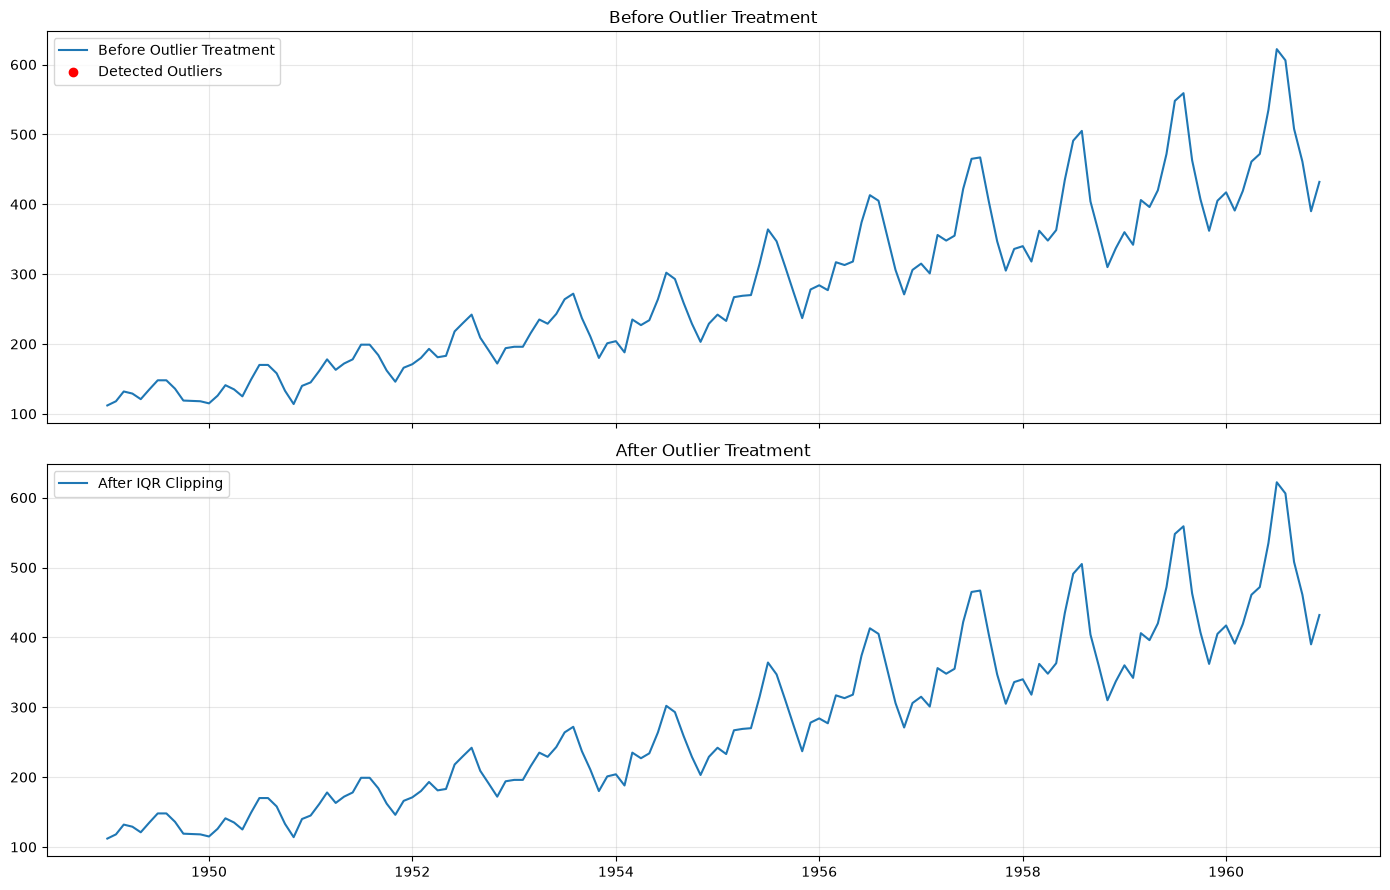

In [28]:
# Dữ liệu trước xử lý outliers
before = series.copy()

# Xử lý bằng IQR clipping
after = series.clip(
    lower=lower_bound,
    upper=upper_bound
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(before, label="Before Outlier Treatment")
axes[0].scatter(
    before.index[outlier_iqr],
    before[outlier_iqr],
    color="red",
    label="Detected Outliers",
    zorder=3
)
axes[0].set_title("Before Outlier Treatment")
axes[0].legend()

axes[1].plot(after, label="After IQR Clipping")
axes[1].set_title("After Outlier Treatment")
axes[1].legend()

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Kết luận: Kiểm tra và xử lý chất lượng dữ liệu

### 1. Missing Values

Một số giá trị NaN được tạo giả lập để kiểm tra khả năng xử lý dữ liệu thiếu. Phương pháp Forward-fill điền giá trị thiếu bằng quan sát hợp lệ gần nhất ở phía trước, trong khi Interpolation ước lượng giá trị dựa trên các quan sát lân cận.

Đối với chuỗi Air Passengers, Interpolation có thể phù hợp khi cần ước lượng các điểm thiếu nằm giữa những tháng đã quan sát. Tuy nhiên, việc lựa chọn phương pháp cần phụ thuộc vào vị trí và cơ chế phát sinh missing.

### 2. Outliers

IQR được sử dụng để phát hiện những quan sát lệch đáng kể so với dữ liệu xung quanh hoặc phân phối tổng thể. Các điểm được đánh dấu chỉ là những ứng viên outlier, không nhất thiết là dữ liệu sai.

Do Air Passengers có xu hướng tăng và tính mùa vụ theo chu kỳ 12 tháng, một số đỉnh hành khách có thể bị đánh dấu nhầm. Vì vậy, cần kiểm tra nguyên nhân trước khi xóa hoặc thay thế các giá trị này.

### 3. Đánh giá sau xử lý

Sau khi điền missing, chuỗi dữ liệu đầy đủ hơn và thuận tiện cho phân tích tiếp theo. Nếu áp dụng clipping, các giá trị nằm ngoài ngưỡng IQR sẽ được giới hạn về ngưỡng tương ứng, làm giảm ảnh hưởng của các giá trị cực đoan nhưng cũng có thể làm mất thông tin mùa vụ.

Nhìn chung, nên ưu tiên giữ nguyên các quan sát hợp lệ, lựa chọn phương pháp điền missing phù hợp với chuỗi thời gian và chỉ xử lý outliers khi có đủ căn cứ.

Vẽ rolling mean (window=12) và rolling std

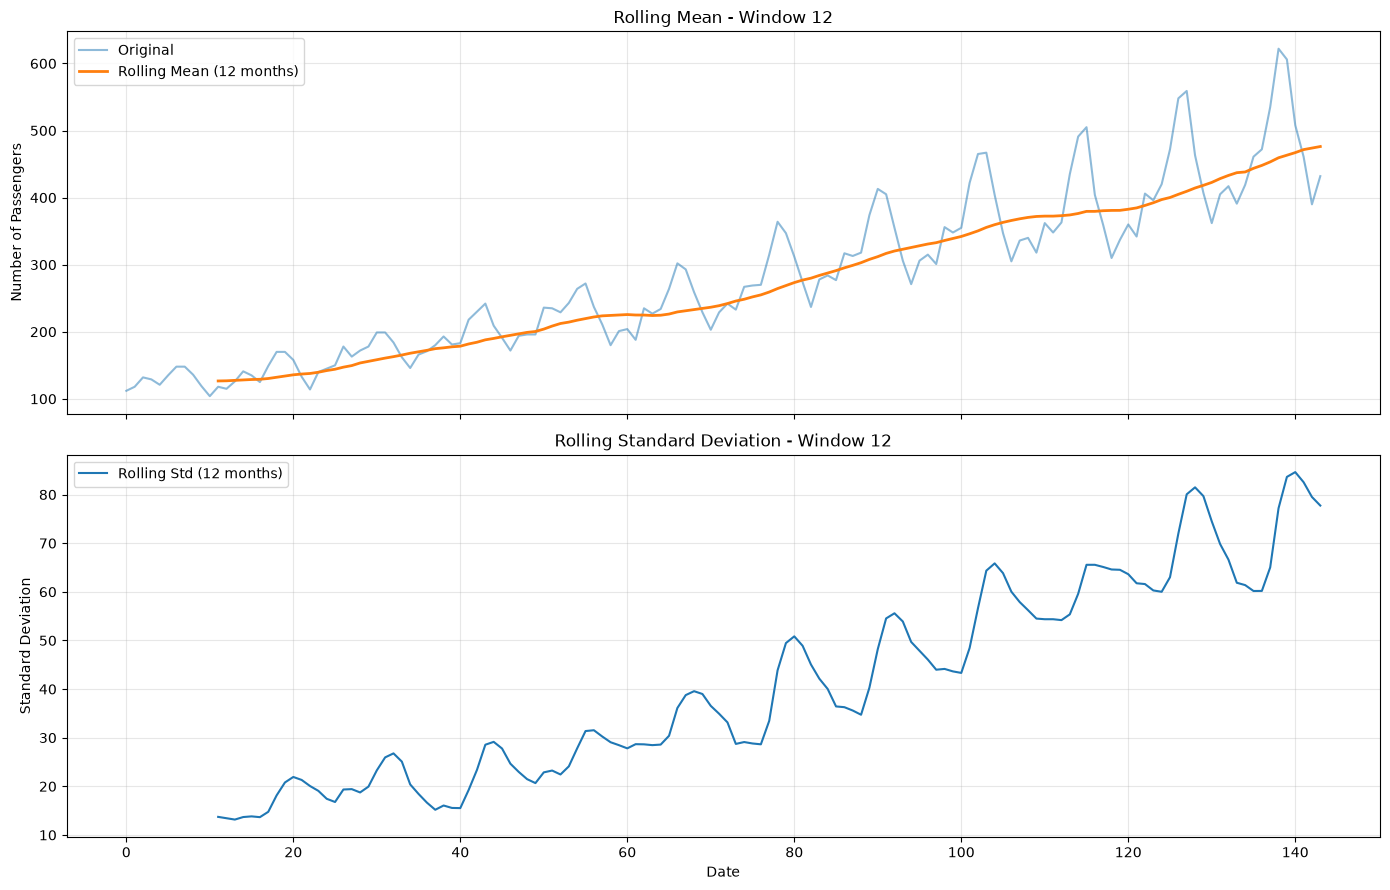

In [29]:
df["rolling_mean"] = df["value"].rolling(window=12).mean()
df["rolling_std"] = df["value"].rolling(window=12).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Rolling Mean
axes[0].plot(
    df.index, df["value"],
    label="Original", alpha=0.5
)
axes[0].plot(
    df.index, df["rolling_mean"],
    label="Rolling Mean (12 months)", linewidth=2
)
axes[0].set_title("Rolling Mean - Window 12")
axes[0].set_ylabel("Number of Passengers")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Rolling Standard Deviation
axes[1].plot(
    df.index, df["rolling_std"],
    label="Rolling Std (12 months)"
)
axes[1].set_title("Rolling Standard Deviation - Window 12")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Standard Deviation")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Vẽ seasonal plot theo tháng (đối với dữ liệu theo tháng).

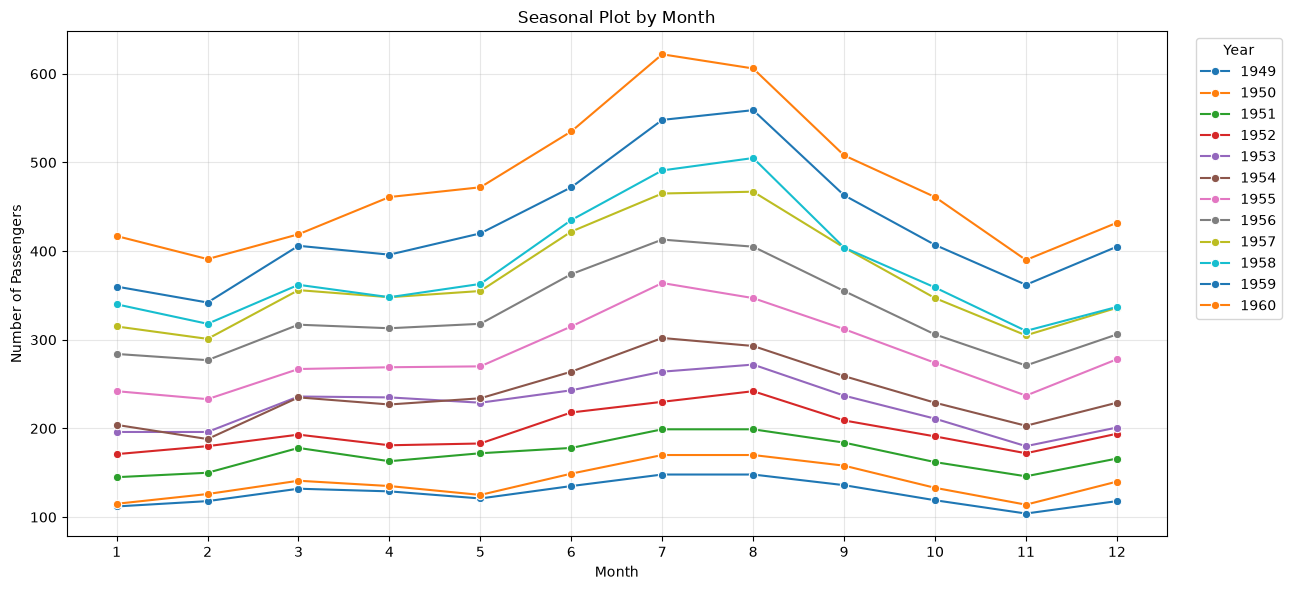

In [32]:
import seaborn as sn
df["year"] = df['date'].dt.year
df["month"] = df['date'].dt.month

plt.figure(figsize=(13, 6))

sn.lineplot(
    data=df.reset_index(),
    x="month",
    y="value",
    hue="year",
    marker="o",
    palette="tab10"
)

plt.title("Seasonal Plot by Month")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Vẽ heatmap seasonality (month × year)

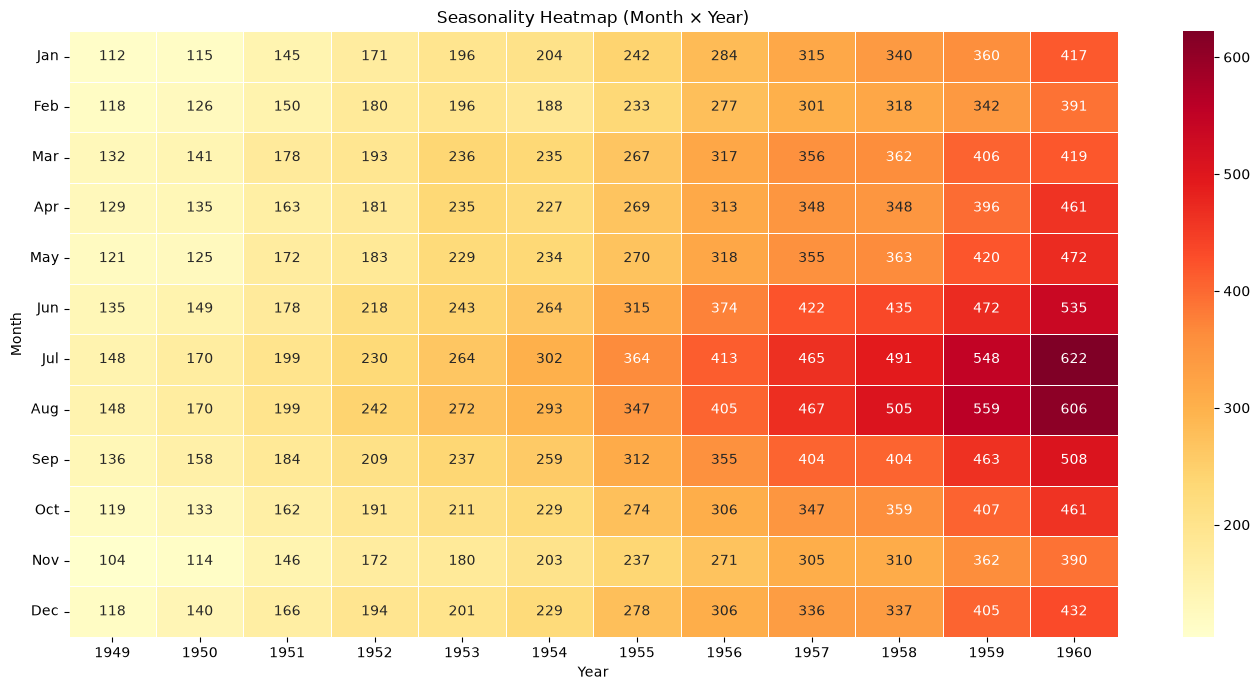

In [33]:
# Tạo bảng: hàng = tháng, cột = năm
seasonal_data = df.pivot_table(
    index="month",
    columns="year",
    values="value",
    aggfunc="mean"
)

plt.figure(figsize=(14, 7))

sn.heatmap(
    seasonal_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.5
)

plt.title("Seasonality Heatmap (Month × Year)")
plt.xlabel("Year")
plt.ylabel("Month")
plt.yticks(
    ticks=[i + 0.5 for i in range(12)],
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ],
    rotation=0
)
plt.tight_layout()
plt.show()

### Kết luận 

**1. Xu hướng chung (Trend)**

Số lượng hành khách có xu hướng tăng dần theo thời gian. Điều này cho thấy nhu cầu vận chuyển hàng không tăng lên trong giai đoạn quan sát.

**2. Tính mùa vụ (Seasonality)**

Dữ liệu thể hiện tính mùa vụ rõ rệt. Số lượng hành khách thường tăng cao vào mùa hè, đặc biệt khoảng tháng 7–8, và giảm vào những tháng đầu năm. Mẫu hình này lặp lại qua nhiều năm.

**3. Mức độ biến động**

Rolling Mean cho thấy xu hướng tăng dài hạn. Rolling Standard Deviation có xu hướng tăng, cho thấy mức độ biến động tuyệt đối lớn hơn ở giai đoạn sau. Điều này có thể liên quan đến xu hướng tăng và biên độ mùa vụ, không nhất thiết là dấu hiệu bất thường.

**4. Bất thường (Anomalies)**

Quan sát biểu đồ để xác định các điểm lệch đáng kể so với xu hướng và mùa vụ thông thường. Không nên kết luận một điểm là bất thường chỉ vì giá trị của nó cao; cần xem xét cả thời điểm, xu hướng và mẫu hình mùa vụ.

**Kết luận chung:** Chuỗi dữ liệu có xu hướng tăng, tính mùa vụ theo tháng rõ rệt và mức biến động tuyệt đối tăng theo thời gian. Đây là những đặc điểm quan trọng cần xem xét trước khi xây dựng mô hình dự báo chuỗi thời gian.